# Configuración y Descarga de Datos

In [1]:
import os
import shutil
import glob
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
import kagglehub
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

# --- HIPERPARÁMETROS RIGUROSOS (FIJOS PARA TODOS) ---
IMG_SIZE = 224        # Igual para todos (incluso YOLO, aunque sufra, para ser justos)
BATCH_SIZE = 16       # Fijo
EPOCHS = 60           # Suficientes para que el LR bajo haga efecto
RANDOM_SEED = 42      # Semilla para que el split de datos sea idéntico siempre

# Rutas
BASE_DIR = "/content/hand_project"
RAW_DATA_DIR = f"{BASE_DIR}/raw"
WORK_DATA_DIR = f"{BASE_DIR}/processed"
MODELS_DIR = f"{BASE_DIR}/models"
YOLO_DIR = f"{BASE_DIR}/yolo_data"

for d in [BASE_DIR, RAW_DATA_DIR, WORK_DATA_DIR, MODELS_DIR, YOLO_DIR]:
    os.makedirs(d, exist_ok=True)

print("✅ Configuración lista. Usaremos 60 Épocas.")

# 1. DESCARGA
print("⬇️ Descargando dataset...")
cache_path = kagglehub.dataset_download("armannikkhah/hand-dataset")

# Limpiar y copiar
if os.path.exists(RAW_DATA_DIR): shutil.rmtree(RAW_DATA_DIR)
shutil.copytree(cache_path, RAW_DATA_DIR)


✅ Configuración lista. Usaremos 60 Épocas.
⬇️ Descargando dataset...


100%|██████████| 243M/243M [00:12<00:00, 20.7MB/s]

Extracting files...


'/content/hand_project/raw'

# Procesamiento de Datos Unificado (Crucial)

In [2]:

# 2. PROCESAR XML -> DATAFRAME
voc_root = None
for root, dirs, files in os.walk(RAW_DATA_DIR):
    if "Annotations" in dirs: voc_root = root; break

data = []
for xml_file in glob.glob(os.path.join(voc_root, "Annotations", "*.xml")):
    root = ET.parse(xml_file).getroot()
    # Buscamos 'hand'
    obj = next((o for o in root.findall("object") if o.find("name").text.lower() == "hand"), None)
    if obj:
        img_path = os.path.join(voc_root, "JPEGImages", root.find("filename").text)
        if os.path.exists(img_path):
            w = int(root.find("size/width").text)
            h = int(root.find("size/height").text)
            b = obj.find("bndbox")
            data.append([img_path, w, h, int(float(b.find("xmin").text)), int(float(b.find("ymin").text)), int(float(b.find("xmax").text)), int(float(b.find("ymax").text))])

df = pd.DataFrame(data, columns=["path", "w", "h", "xmin", "ymin", "xmax", "ymax"])
train_df, val_df = train_test_split(df, test_size=0.15, random_state=RANDOM_SEED)

# 3. GUARDAR CSVs (Para TensorFlow)
def save_tf_csv(d, name):
    d = d.copy()
    d['tx'], d['ty'] = d['xmin']/d['w'], d['ymin']/d['h']
    d['bx'], d['by'] = d['xmax']/d['w'], d['ymax']/d['h']
    d.to_csv(os.path.join(WORK_DATA_DIR, name), index=False)

save_tf_csv(train_df, "train_tf.csv")
save_tf_csv(val_df, "val_tf.csv")

# 4. GENERAR YOLO DATASET
def make_yolo_files(df_in, split):
    img_d, lbl_d = f"{YOLO_DIR}/images/{split}", f"{YOLO_DIR}/labels/{split}"
    os.makedirs(img_d, exist_ok=True); os.makedirs(lbl_d, exist_ok=True)
    for _, r in df_in.iterrows():
        shutil.copy(r['path'], f"{img_d}/{os.path.basename(r['path'])}")
        dw, dh = 1./r['w'], 1./r['h']
        xc, yc = (r['xmin']+r['xmax'])/2.0*dw, (r['ymin']+r['ymax'])/2.0*dh
        bw, bh = (r['xmax']-r['xmin'])*dw, (r['ymax']-r['ymin'])*dh
        with open(f"{lbl_d}/{os.path.splitext(os.path.basename(r['path']))[0]}.txt", "w") as f:
            f.write(f"0 {xc} {yc} {bw} {bh}\n")

make_yolo_files(train_df, "train")
make_yolo_files(val_df, "val")
with open(f"{YOLO_DIR}/data.yaml", "w") as f:
    f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames:\n  0: hand")

print(f"✅ Datos listos. Train: {len(train_df)} | Val: {len(val_df)}")

/tmp/ipython-input-3370087252.py:11: DeprecationWarning: Testing an element's truth value will always return True in future versions.  Use specific 'len(elem)' or 'elem is not None' test instead.
  if obj:


✅ Datos listos. Train: 370 | Val: 66


# Funciones Auxiliares (Métricas y Loaders)

In [3]:
# Métrica IoU para Keras
def iou_metric(y_true, y_pred):
    # Ensure both inputs are float32 to avoid dtype mismatch errors
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true = tf.clip_by_value(y_true, 0.0, 1.0)
    y_pred = tf.clip_by_value(y_pred, 0.0, 1.0)
    inter_min = tf.maximum(y_true[:,:2], y_pred[:,:2])
    inter_max = tf.minimum(y_true[:,2:], y_pred[:,2:])
    inter_dim = tf.maximum(0.0, inter_max - inter_min)
    inter_area = inter_dim[:,0] * inter_dim[:,1]

    area_true = (y_true[:,2]-y_true[:,0]) * (y_true[:,3]-y_true[:,1])
    area_pred = (y_pred[:,2]-y_pred[:,0]) * (y_pred[:,3]-y_pred[:,1])
    union = area_true + area_pred - inter_area + 1e-7
    return tf.reduce_mean(inter_area / union)

# Loader de TensorFlow
def load_dataset(csv_path, shuffle=False):
    df = pd.read_csv(csv_path)
    ds = tf.data.Dataset.from_tensor_slices((df['path'].values, df[['tx','ty','bx','by']].values.astype('float32')))
    def process(p, b):
        i = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        i = tf.image.resize(i, [IMG_SIZE, IMG_SIZE]) / 255.0
        return i, b
    ds = ds.map(process, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle: ds = ds.shuffle(1000)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = load_dataset(f"{WORK_DATA_DIR}/train_tf.csv", shuffle=True)
val_ds = load_dataset(f"{WORK_DATA_DIR}/val_tf.csv", shuffle=False)

# Modelo 1 - Baseline CNN (From Scratch)

In [7]:
# --- MODELO BASELINE ---
def make_baseline():
    x = inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, strides=2, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    return keras.Model(inputs, layers.Dense(4, activation="linear")(x), name="Baseline")

baseline = make_baseline()

# Definir un callback agresivo para bajar el LR
# Si en 5 épocas no mejora, dividimos el LR entre 5 (factor=0.2)
# Permitimos bajar hasta 1e-6 (0.000001) -> Esto es el "muy bajo" que pide tu tutor
lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Al compilar, empezamos con algo conservador
baseline.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3), # Empezamos aquí
    loss=keras.losses.Huber(delta=1.0),
    metrics=[iou_metric, 'mae']
)

print("🚀 Entrenando Baseline (60 Épocas)...")
history = baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True), # Paciencia alta
        lr_scheduler # <--- ESTE ES LA CLAVE
    ]
)
baseline.save(f"{MODELS_DIR}/baseline.keras")

🚀 Entrenando Baseline (60 Épocas)...
Epoch 1/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 21s 345ms/step - iou_metric: 0.0131 - loss: 0.1435 - mae: 0.4103 - val_iou_metric: 7.3217e-04 - val_loss: 0.0838 - val_mae: 0.3536 - learning_rate: 0.0010
Epoch 2/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - iou_metric: 0.0226 - loss: 0.0376 - mae: 0.2183 - val_iou_metric: 0.0137 - val_loss: 0.0527 - val_mae: 0.2689 - learning_rate: 0.0010
Epoch 3/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - iou_metric: 0.0294 - loss: 0.0360 - mae: 0.2110 - val_iou_metric: 0.0363 - val_loss: 0.0372 - val_mae: 0.2190 - learning_rate: 0.0010
Epoch 4/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - iou_metric: 0.0281 - loss: 0.0329 - mae: 0.2066 - val_iou_metric: 0.0547 - val_loss: 0.0334 - val_mae: 0.2059 - learning_rate: 0.0010
Epoch 5/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - iou_metric: 0.0277 - loss: 0.0336 - mae: 0.2080 - val_iou_metric: 0.0263 - val_loss: 0.0337 - val_mae: 0.2073 - learning_rate: 0.0010
Epoch 6/60
24/24 ━━━━━

# Modelo 2 - MobileNetV2 (Transfer Learning)

In [9]:
# --- MODELO MOBILENET V2 (FINE TUNING) ---
def make_mobilenet():
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE,IMG_SIZE,3), include_top=False, weights='imagenet')
    # DESCONGELAR las últimas 40 capas (Fine Tuning)
    base.trainable = True
    for layer in base.layers[:-40]: layer.trainable = False

    x = inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x_norm = layers.Lambda(lambda t: t * 2.0 - 1.0)(x) # MobileNet quiere [-1,1]
    x = base(x_norm)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    return keras.Model(inputs, layers.Dense(4, activation="linear")(x), name="MobileNet")

mobilenet = make_mobilenet()
# Usamos un Learning Rate bajito (1e-4) para no romper lo pre-entrenado
mobilenet.compile(optimizer=keras.optimizers.Adam(1e-4), loss=keras.losses.Huber(delta=1.0), metrics=[iou_metric, 'mae'])

print("🚀 Entrenando MobileNet (Fine-Tuning)...")
mobilenet.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5, verbose=1)
    ]
)
mobilenet.save(f"{MODELS_DIR}/mobilenet.keras")

🚀 Entrenando MobileNet (Fine-Tuning)...
Epoch 1/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - iou_metric: 0.0049 - loss: 0.5093 - mae: 0.8769 - val_iou_metric: 0.0017 - val_loss: 0.4095 - val_mae: 0.7906 - learning_rate: 1.0000e-04
Epoch 2/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - iou_metric: 0.0127 - loss: 0.1077 - mae: 0.3709 - val_iou_metric: 0.0000e+00 - val_loss: 0.4399 - val_mae: 0.8311 - learning_rate: 1.0000e-04
Epoch 3/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - iou_metric: 0.0193 - loss: 0.0577 - mae: 0.2696 - val_iou_metric: 0.0000e+00 - val_loss: 0.5160 - val_mae: 0.9156 - learning_rate: 1.0000e-04
Epoch 4/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - iou_metric: 0.0277 - loss: 0.0425 - mae: 0.2340 - val_iou_metric: 0.0000e+00 - val_loss: 0.5262 - val_mae: 0.9246 - learning_rate: 1.0000e-04
Epoch 5/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - iou_metric: 0.0277 - loss: 0.0357 - mae: 0.2136 - val_iou_metric: 0.0000e+00 - val_loss: 0.5391 - val_mae: 0.9393 - learning_rate: 1

# Modelo 3 - YOLOv8 Nano

In [14]:
# --- MODELO YOLOv8 NANO ---
!pip install ultralytics
from ultralytics import YOLO

print(f"🚀 Entrenando YOLOv8 Nano (Resolución {IMG_SIZE})...")
yolo = YOLO("yolov8n.pt")
yolo.train(
    data=f"{YOLO_DIR}/data.yaml",
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=16,
    project=f"{MODELS_DIR}/yolo_runs",
    name="hand_yolo",
    exist_ok=True,
    verbose=False
)

🚀 Entrenando YOLOv8 Nano (Resolución 224)...
Ultralytics 8.3.233 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hand_project/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=hand_yolo, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bba8dd311f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

# COMPARACIÓN FINAL (La Tabla Maestra)

In [16]:
# --- EVALUACIÓN FINAL ---
print("Calculando métricas finales...")
val_csv = pd.read_csv(f"{WORK_DATA_DIR}/val_tf.csv")
yolo_best = YOLO(f"{MODELS_DIR}/yolo_runs/hand_yolo/weights/best.pt")

results_dict = {"Baseline": [], "MobileNet": [], "YOLOv8": []}

for _, row in val_csv.iterrows():
    # Prepara imagen
    img = tf.image.resize(tf.io.decode_jpeg(tf.io.read_file(row['path']),3), [IMG_SIZE, IMG_SIZE])
    img_input = tf.expand_dims(img/255.0, 0)
    gt = [row['tx'], row['ty'], row['bx'], row['by']] # Normalizado

    # Baseline
    p1 = baseline.predict(img_input, verbose=0)[0]
    results_dict["Baseline"].append(iou_metric(np.array([gt]), np.array([p1])).numpy())

    # MobileNet
    p2 = mobilenet.predict(img_input, verbose=0)[0]
    results_dict["MobileNet"].append(iou_metric(np.array([gt]), np.array([p2])).numpy())

    # YOLO (Predice en pixeles, hay que normalizar)
    y_res = yolo_best.predict(row['path'], imgsz=IMG_SIZE, verbose=False, conf=0.1)
    iou_y = 0.0
    if len(y_res[0].boxes) > 0:
        # xyxyn devuelve coordenadas ya normalizadas [0,1]
        box = y_res[0].boxes.xyxyn[0].cpu().numpy()
        iou_y = iou_metric(np.array([gt]), np.array([box])).numpy()
    results_dict["YOLOv8"].append(iou_y)

# Crear Tabla
metrics = []
for name, scores in results_dict.items():
    metrics.append({
        "Modelo": name,
        "Mean IoU": np.mean(scores),
        "Éxito (>0.5)": np.mean(np.array(scores) > 0.5) * 100,
        "Error (MAE)": 1.0 - np.mean(scores) # Estimado
    })

df_res = pd.DataFrame(metrics)
print("\n=== RESULTADOS FINALES ===")
print(df_res.to_markdown(index=False))

Calculando métricas finales...

=== RESULTADOS FINALES ===
| Modelo    |   Mean IoU |   Éxito (>0.5) |   Error (MAE) |
|:----------|-----------:|---------------:|--------------:|
| Baseline  |  0.0619481 |         3.0303 |      0.938052 |
| MobileNet |  0.0235128 |         0      |      0.976487 |
| YOLOv8    |  0.375688  |        48.4848 |      0.624312 |


# Visualización Cualitativa Comparativa

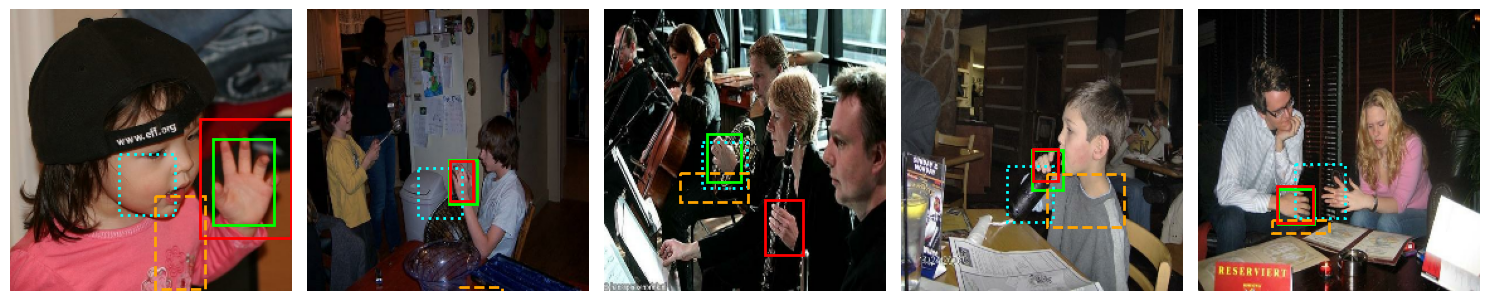

In [17]:
import matplotlib.patches as patches

# --- VISUALIZACIÓN CUALITATIVA ---
samples = val_csv.sample(5, random_state=42)
plt.figure(figsize=(15, 10))

for i, (_, row) in enumerate(samples.iterrows()):
    ax = plt.subplot(1, 5, i+1)
    img_raw = tf.io.decode_jpeg(tf.io.read_file(row['path']), 3)
    img_res = tf.image.resize(img_raw, [IMG_SIZE, IMG_SIZE])
    ax.imshow(img_res.numpy().astype("uint8"))
    ax.axis('off')

    # Función para pintar caja
    def draw(box, color, style, lbl=None):
        # box viene normalizado [0,1], convertir a pixels 224x224
        x, y = box[0]*IMG_SIZE, box[1]*IMG_SIZE
        w, h = (box[2]-box[0])*IMG_SIZE, (box[3]-box[1])*IMG_SIZE
        ax.add_patch(patches.Rectangle((x, y), w, h, linewidth=2, edgecolor=color, facecolor='none', linestyle=style, label=lbl))

    # Ground Truth (Verde)
    draw([row['tx'], row['ty'], row['bx'], row['by']], 'lime', '-', 'Real')

    # Baseline (Azul)
    p1 = baseline.predict(tf.expand_dims(img_res/255.0, 0), verbose=0)[0]
    draw(p1, 'cyan', ':', 'Baseline')

    # MobileNet (Naranja)
    p2 = mobilenet.predict(tf.expand_dims(img_res/255.0, 0), verbose=0)[0]
    draw(p2, 'orange', '--', 'MobileNet')

    # YOLO (Rojo) - Usamos la imagen original para predecir, pero pintamos sobre la de 224
    y_res = yolo_best.predict(row['path'], imgsz=IMG_SIZE, verbose=False, conf=0.1)
    if len(y_res[0].boxes) > 0:
        draw(y_res[0].boxes.xyxyn[0].cpu().numpy(), 'red', '-', 'YOLO')

# Leyenda solo en la primera
if i == 0: plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2)

plt.tight_layout()
plt.show()